### This notebook is used to study what type of experimental data we have available to model.

In [1]:
import sys
import os
from pathlib import Path

def find_project_root(start):
    for base in [start, *start.parents]:
        for candidate in [base, base / "barrier-extraction"]:
            if (candidate / "src").is_dir() and (candidate / "data").is_dir():
                return candidate
    raise FileNotFoundError("Could not locate barrier-extraction project root containing src/ and data/.")

PROJECT_ROOT = find_project_root(Path.cwd().resolve())
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

DATA_DIR = PROJECT_ROOT / "data"
PLOT_DIR = PROJECT_ROOT / "plots"
PLOT_DIR.mkdir(exist_ok=True)
EXPERIMENT_DATA_DIR = DATA_DIR / "experimental"


import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from src.wong import sigma
import scienceplots
plt.style.use(['science', 'no-latex', 'ieee'])

import scipy as sp
from scipy.optimize import curve_fit
from sklearn.gaussian_process import GaussianProcessRegressor
from sklearn.gaussian_process.kernels import RBF, WhiteKernel, Matern, ConstantKernel, ExpSineSquared, RationalQuadratic
import findiff as fd



plt.rc('xtick', labelsize=24)
plt.rc('ytick', labelsize=24)
plt.rc('axes', labelsize=24)
plt.rc('legend', fontsize=24)    # all future legends will be 14-pt


/opt/software-current/2023.06/x86_64/intel/skylake_avx512/software/Python-bundle-PyPI/2023.06-GCCcore-12.3.0/lib/python3.11/site-packages/pyparsing/core.py:5596: SyntaxWarning: 'return' in a 'finally' block
  return self.__class__.__name__ + ": " + retString


### Examine the resolution of the different systems we want to model to obtain order of magnitude

Mean spacing = 0.50 MeV
Std spacing  = 0.00 MeV
CV           = 0.00
Average resolution for Montagnoli et al. 2012: 0.50 MeV
Median   resolution for Montagnoli et al. 2012: 0.50 MeV
Min/Max  resolution for Montagnoli et al. 2012: 0.50/0.50 MeV


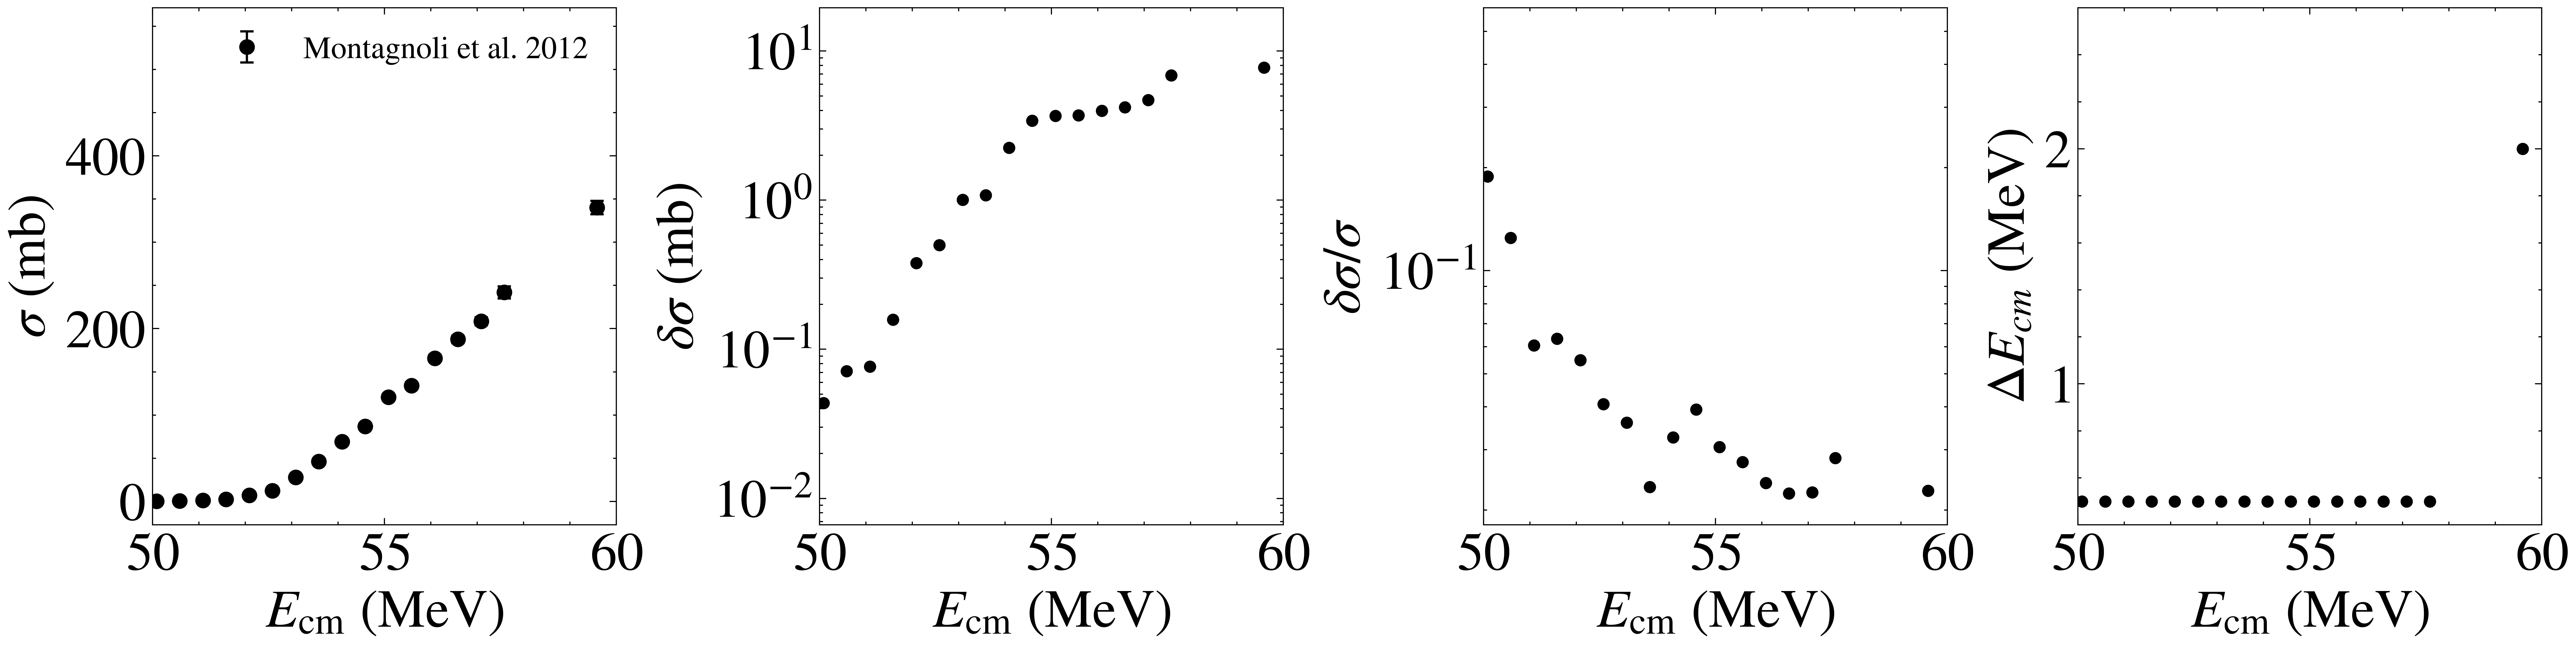

In [2]:
#### SYSTEM ####

dirname = EXPERIMENT_DATA_DIR / "40Ca40Ca_exp"
system = "$^{40}$Ca+$^{40}$Ca"
fileprefix = dirname

expfiles = [ 'expMont.dat' ]
explabel = [ 'Montagnoli et al. 2012']
expmarker = [ 'o', 's' ]
expcolor = [ 'k', 'g' ]

exp = []

for file in expfiles:
    tmpdf = pd.read_csv(os.path.join(dirname,file),sep=r"\s+",names=['Ecm','Sigma','Error'])
    if(tmpdf['Ecm'].iloc[0] > tmpdf['Ecm'].iloc[-1]):
        exp.append(tmpdf.iloc[::-1])
    else:
        exp.append(tmpdf)

xmin = 50.0
xmax = 60.0

# --- 1) Compute & print resolutions per experiment ---
for i in range(len(exp)):
    E_data     = exp[i]['Ecm'].to_numpy()
    error_data = exp[i]['Error'].to_numpy()
    Sigma_data = exp[i]['Sigma'].to_numpy()
    
    safe_label = explabel[i].replace(" ", "")
    np.save(DATA_DIR / f"E_{safe_label}.npy", E_data)
    np.save(DATA_DIR / f"sigma_{safe_label}.npy", Sigma_data)
    np.save(DATA_DIR / f"error_{safe_label}.npy", error_data)

    # stop at closest point to 80 MeV
    stop = np.argmin(np.abs(E_data - 60.0))
    E_sorted = np.sort(E_data[:stop])
    dE       = np.diff(E_sorted)
    mean_dE = dE.mean()
    std_dE  = dE.std()
    cv      = std_dE/mean_dE
    print(f"Mean spacing = {mean_dE:.2f} MeV")
    print(f"Std spacing  = {std_dE:.2f} MeV")
    print(f"CV           = {cv:.2f}")

    if dE.size:
        print(f"Average resolution for {explabel[i]}: {dE.mean():.2f} MeV")
        print(f"Median   resolution for {explabel[i]}: {np.median(dE):.2f} MeV")
        print(f"Min/Max  resolution for {explabel[i]}: {dE.min():.2f}/{dE.max():.2f} MeV")
    else:
        print(f"No resolution data for {explabel[i]} (too few points).")


# — plotting —
fig, axes = plt.subplots(1, 4, figsize=(16,4), sharex=True, constrained_layout=True)
#fig.suptitle(system, fontsize=30, y=1.1)

# σ(E)
ax = axes[0]
for df, m, c, lbl in zip(exp, expmarker, expcolor, explabel):
    if df['Error'].any():
        ax.errorbar(
            df['Ecm'], 
            df['Sigma'], 
            yerr=df['Error'],         # <-- add y-error here
            fmt=m,                    # marker style
            color=c, 
            label=lbl,
            capsize=3,                # little horizontal caps on the error bars
            linestyle='none',         # no connecting line
            markersize=6
        )
    else:
        ax.scatter(df['Ecm'], df['Sigma'], 
                   s=20, marker=m, color=c, label=lbl)
ax.set_xlabel(r'$E_{\rm cm}$ (MeV)')
ax.set_ylabel(r'$\sigma$ (mb)')
ax.set_xlim(xmin, xmax)
#ax.grid(True, linestyle='--', alpha=0.4)
ax.legend(fontsize=14)
#ax.set_title(r'Absolute cross-section')

# δσ(E)
ax = axes[1]
for df, m, c in zip(exp, expmarker, expcolor):
    ax.scatter(df['Ecm'], df['Error'], 
               s=20, marker=m, color=c)
ax.set_xlabel(r'$E_{\rm cm}$ (MeV)')
ax.set_ylabel(r'$\delta\sigma$ (mb)')
ax.set_yscale('log')
ax.set_xlim(xmin, xmax)
#ax.grid(True, which='both', linestyle='--', alpha=0.4)
#ax.set_title(system, fontsize=24)

# δσ/σ
ax = axes[2]
for df, m, c in zip(exp, expmarker, expcolor):
    ax.scatter(df['Ecm'], df['Error']/df['Sigma'], 
               s=20, marker=m, color=c)
ax.set_xlabel(r'$E_{\rm cm}$ (MeV)')
ax.set_ylabel(r'$\delta\sigma/\sigma$')
ax.set_yscale('log')
ax.set_xlim(xmin, xmax)

# --- 5) Plot del E ---
#plt.figure(figsize=(8,5))
ax = axes[3]
for df, m, c in zip(exp, expmarker, expcolor):
    ax.scatter(df['Ecm'][1:], np.diff(df['Ecm']), 
               s=20, marker=m, color=c)
ax.set_xlabel(r'$E_{\rm cm}$ (MeV)')
ax.set_ylabel(r'$\Delta E_{cm}$ (MeV)')
ax.set_xlim(xmin, xmax)
#plt.tight_layout()
fig.savefig(PLOT_DIR / '40Ca40Ca.png', dpi=300)
plt.show()

Mean spacing = 0.56 MeV
Std spacing  = 0.00 MeV
CV           = 0.01
Average resolution for Morton et al. 1999: 0.56 MeV
Median   resolution for Morton et al. 1999: 0.56 MeV
Min/Max  resolution for Morton et al. 1999: 0.55/0.56 MeV
Mean spacing = 1.03 MeV
Std spacing  = 0.27 MeV
CV           = 0.26
Average resolution for Dasgupta et al. 2007: 1.03 MeV
Median   resolution for Dasgupta et al. 2007: 1.02 MeV
Min/Max  resolution for Dasgupta et al. 2007: 0.45/1.70 MeV


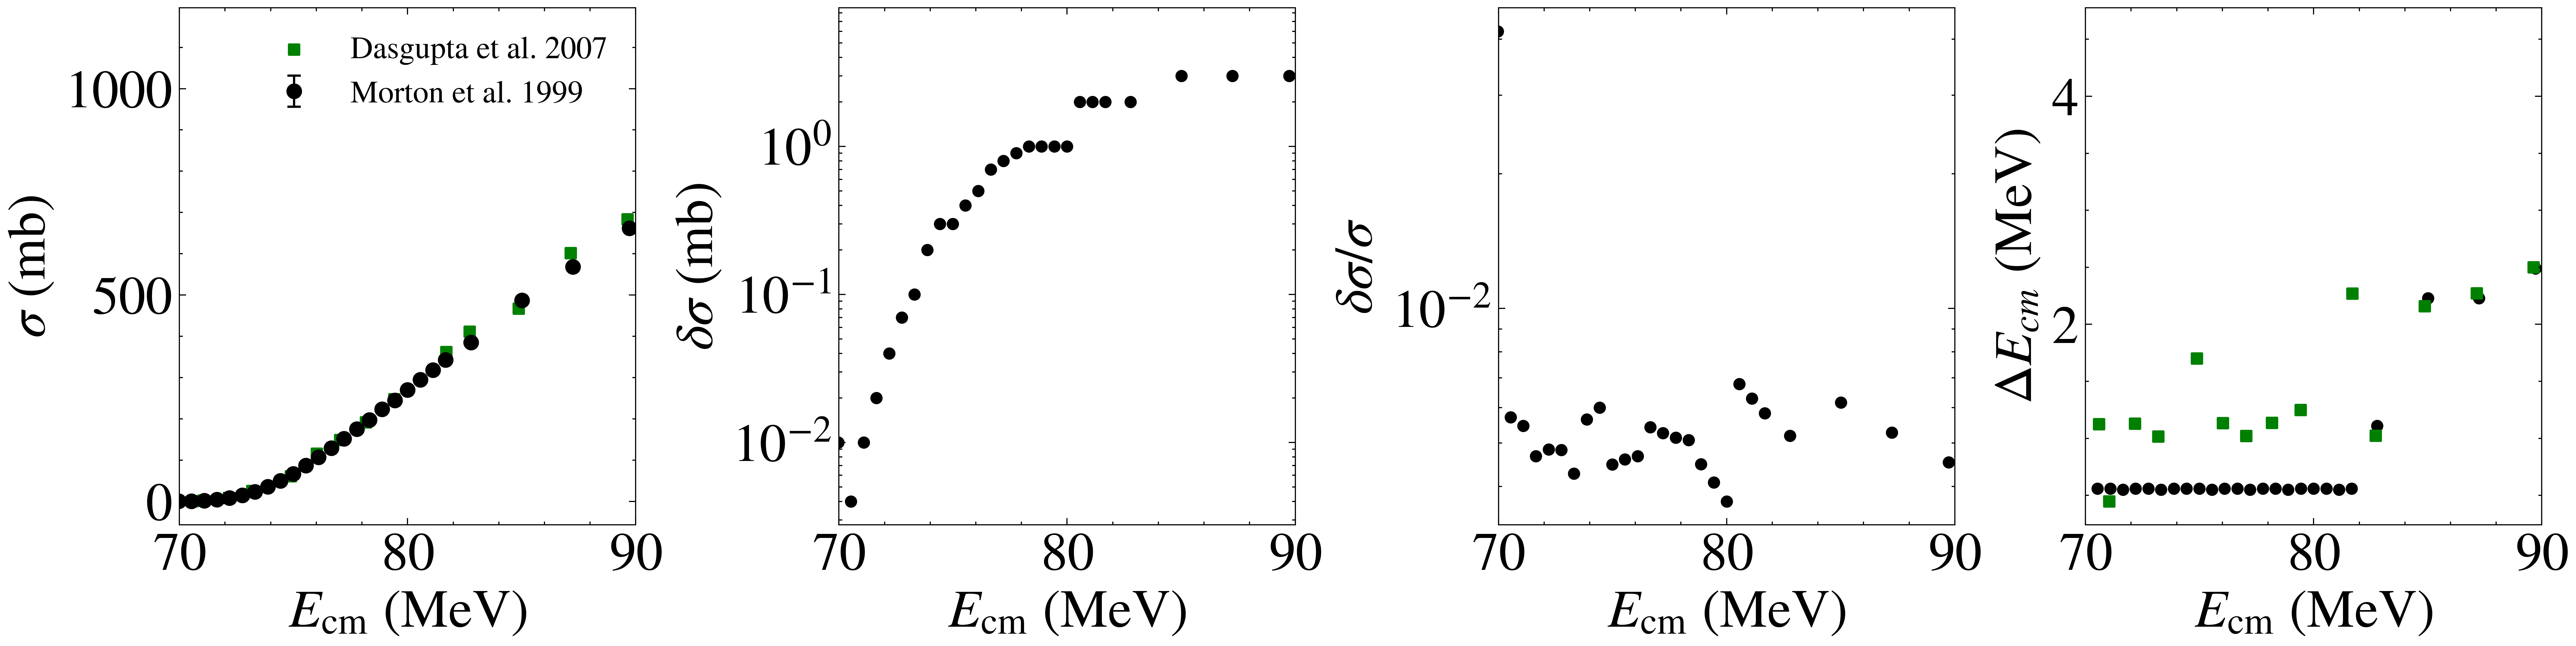

In [3]:
#### SYSTEM ####

dirname = EXPERIMENT_DATA_DIR / "16O208Pb_exp"
system = "$^{208}$Pb+$^{16}$O"
fileprefix = dirname

expfiles = [ 'expMort.dat', 'expDas.dat' ]
explabel = [ 'Morton et al. 1999', 'Dasgupta et al. 2007' ]
expmarker = [ 'o', 's' ]
expcolor = [ 'k', 'g' ]

exp = []

for file in expfiles:
    tmpdf = pd.read_csv(os.path.join(dirname,file),sep=r"\s+",names=['Ecm','Sigma','Error'])
    if(tmpdf['Ecm'].iloc[0] > tmpdf['Ecm'].iloc[-1]):
        exp.append(tmpdf.iloc[::-1])
    else:
        exp.append(tmpdf)

xmin = 70.0
xmax = 90.0

# --- 1) Compute & print resolutions per experiment ---
for i in range(len(exp)):
    E_data     = exp[i]['Ecm'].to_numpy()
    error_data = exp[i]['Error'].to_numpy()
    Sigma_data = exp[i]['Sigma'].to_numpy()

    safe_label = explabel[i].replace(" ", "")
    np.save(DATA_DIR / f"E_{safe_label}.npy", E_data)
    np.save(DATA_DIR / f"sigma_{safe_label}.npy", Sigma_data)
    np.save(DATA_DIR / f"error_{safe_label}.npy", error_data)
    
    # stop at closest point to 80 MeV
    stop = np.argmin(np.abs(E_data - 80.0))
    E_sorted = np.sort(E_data[:stop])
    dE       = np.diff(E_sorted)
    mean_dE = dE.mean()
    std_dE  = dE.std()
    cv      = std_dE/mean_dE
    print(f"Mean spacing = {mean_dE:.2f} MeV")
    print(f"Std spacing  = {std_dE:.2f} MeV")
    print(f"CV           = {cv:.2f}")

    if dE.size:
        print(f"Average resolution for {explabel[i]}: {dE.mean():.2f} MeV")
        print(f"Median   resolution for {explabel[i]}: {np.median(dE):.2f} MeV")
        print(f"Min/Max  resolution for {explabel[i]}: {dE.min():.2f}/{dE.max():.2f} MeV")
    else:
        print(f"No resolution data for {explabel[i]} (too few points).")

# — plotting —
fig, axes = plt.subplots(1, 4, figsize=(16,4), sharex=True, constrained_layout=True)
#fig.suptitle(system, fontsize=30, y=1.1)

# σ(E)
ax = axes[0]
for df, m, c, lbl in zip(exp, expmarker, expcolor, explabel):
    if df['Error'].any():
        ax.errorbar(
            df['Ecm'], 
            df['Sigma'], 
            yerr=df['Error'],         # <-- add y-error here
            fmt=m,                    # marker style
            color=c, 
            label=lbl,
            capsize=3,                # little horizontal caps on the error bars
            linestyle='none',         # no connecting line
            markersize=6
        )
    else:
        ax.scatter(df['Ecm'], df['Sigma'], 
                   s=20, marker=m, color=c, label=lbl)
ax.set_xlabel(r'$E_{\rm cm}$ (MeV)')
ax.set_ylabel(r'$\sigma$ (mb)')
ax.set_xlim(xmin, xmax)
#ax.grid(True, linestyle='--', alpha=0.4)
ax.legend(fontsize=14)
#ax.set_title(r'Absolute cross-section')

# δσ(E)
ax = axes[1]
for df, m, c in zip(exp, expmarker, expcolor):
    ax.scatter(df['Ecm'], df['Error'], 
               s=20, marker=m, color=c)
ax.set_xlabel(r'$E_{\rm cm}$ (MeV)')
ax.set_ylabel(r'$\delta\sigma$ (mb)')
ax.set_yscale('log')
ax.set_xlim(xmin, xmax)
#ax.grid(True, which='both', linestyle='--', alpha=0.4)
#ax.set_title(system, fontsize=24)

# δσ/σ
ax = axes[2]
for df, m, c in zip(exp, expmarker, expcolor):
    ax.scatter(df['Ecm'], df['Error']/df['Sigma'], 
               s=20, marker=m, color=c)
ax.set_xlabel(r'$E_{\rm cm}$ (MeV)')
ax.set_ylabel(r'$\delta\sigma/\sigma$')
ax.set_yscale('log')
ax.set_xlim(xmin, xmax)

# --- 5) Plot del E ---
#plt.figure(figsize=(8,5))
ax = axes[3]
for df, m, c in zip(exp, expmarker, expcolor):
    ax.scatter(df['Ecm'][1:], np.diff(df['Ecm']), 
               s=20, marker=m, color=c)
ax.set_xlabel(r'$E_{\rm cm}$ (MeV)')
ax.set_ylabel(r'$\Delta E_{cm}$ (MeV)')
ax.set_xlim(xmin, xmax)
#plt.tight_layout()
fig.savefig(PLOT_DIR / '208Pb16O.png', dpi=300)
plt.show()

Mean spacing = 0.97 MeV
Std spacing  = 0.67 MeV
CV           = 0.68
Average resolution for Aljuwair et al. 1984: 0.97 MeV
Median   resolution for Aljuwair et al. 1984: 0.58 MeV
Min/Max  resolution for Aljuwair et al. 1984: 0.52/2.73 MeV
Mean spacing = 0.44 MeV
Std spacing  = 0.01 MeV
CV           = 0.02
Average resolution for Trotta et al. 2001: 0.44 MeV
Median   resolution for Trotta et al. 2001: 0.44 MeV
Min/Max  resolution for Trotta et al. 2001: 0.42/0.45 MeV
Mean spacing = 0.79 MeV
Std spacing  = 0.32 MeV
CV           = 0.40
Average resolution for Jiang et al. 2010: 0.79 MeV
Median   resolution for Jiang et al. 2010: 0.87 MeV
Min/Max  resolution for Jiang et al. 2010: 0.44/1.75 MeV


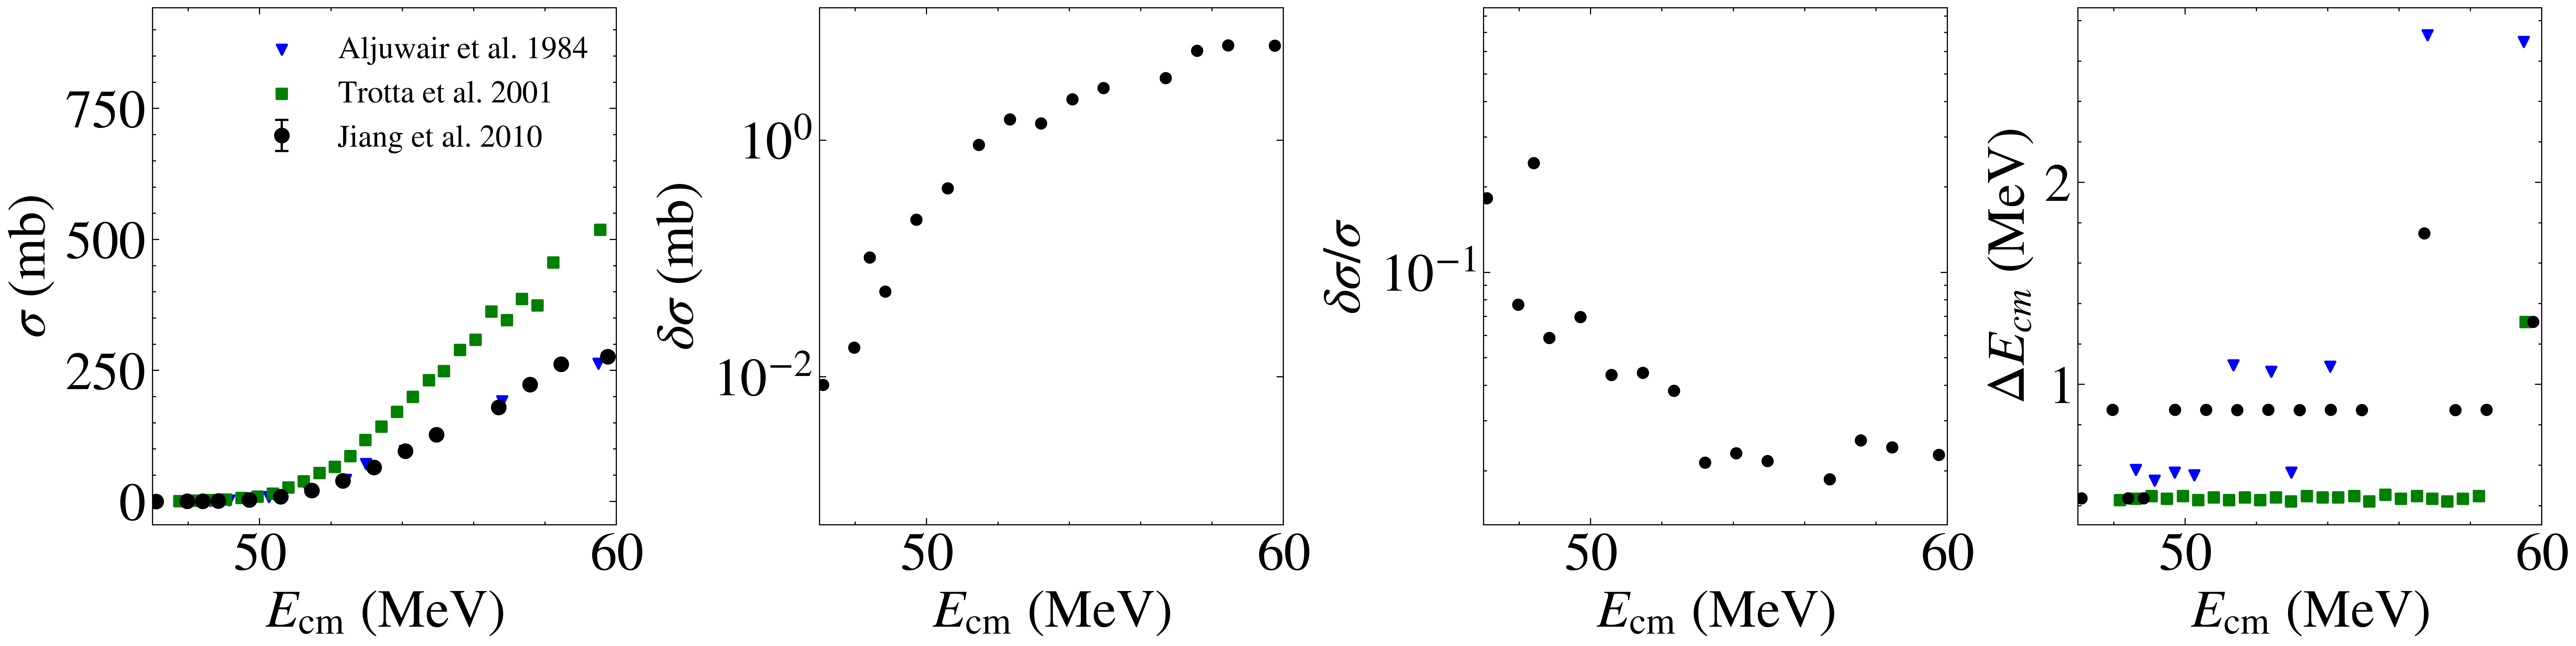

In [4]:
#### SYSTEM ####

dirname = EXPERIMENT_DATA_DIR / "48Ca40Ca_exp"
system = "$^{48}$Ca+$^{40}$Ca"
fileprefix = dirname

expfiles = [ 'expAlj.dat', 'expTrotta.dat', 'expJiang.dat' ]
explabel = [ 'Aljuwair et al. 1984', 'Trotta et al. 2001', 'Jiang et al. 2010']

expmarker = [ 'v', 's', 'o' ]
expcolor = [ 'b', 'g', 'k' ]


exp = []

for file in expfiles:
    tmpdf = pd.read_csv(os.path.join(dirname,file),sep=r"\s+",names=['Ecm','Sigma','Error'])
    if(tmpdf['Ecm'].iloc[0] > tmpdf['Ecm'].iloc[-1]):
        exp.append(tmpdf.iloc[::-1])
    else:
        exp.append(tmpdf)

xmin = 47.0
xmax = 60.0

# --- 1) Compute & print resolutions per experiment ---
for i in range(len(exp)):
    E_data     = exp[i]['Ecm'].to_numpy()
    error_data = exp[i]['Error'].to_numpy()
    Sigma_data = exp[i]['Sigma'].to_numpy()
    
    safe_label = explabel[i].replace(" ", "")
    np.save(DATA_DIR / f"E_{safe_label}.npy", E_data)
    np.save(DATA_DIR / f"sigma_{safe_label}.npy", Sigma_data)
    np.save(DATA_DIR / f"error_{safe_label}.npy", error_data)
    # stop at closest point to 80 MeV
    stop = np.argmin(np.abs(E_data - 60.0))
    E_sorted = np.sort(E_data[:stop])
    dE       = np.diff(E_sorted)
    mean_dE = dE.mean()
    std_dE  = dE.std()
    cv      = std_dE/mean_dE
    print(f"Mean spacing = {mean_dE:.2f} MeV")
    print(f"Std spacing  = {std_dE:.2f} MeV")
    print(f"CV           = {cv:.2f}")

    if dE.size:
        print(f"Average resolution for {explabel[i]}: {dE.mean():.2f} MeV")
        print(f"Median   resolution for {explabel[i]}: {np.median(dE):.2f} MeV")
        print(f"Min/Max  resolution for {explabel[i]}: {dE.min():.2f}/{dE.max():.2f} MeV")
    else:
        print(f"No resolution data for {explabel[i]} (too few points).")

# — plotting —
fig, axes = plt.subplots(1, 4, figsize=(16,4), sharex=True, constrained_layout=True)
#fig.suptitle(system, fontsize=30, y=1.1)

# σ(E)
ax = axes[0]
for df, m, c, lbl in zip(exp, expmarker, expcolor, explabel):
    if df['Error'].any():
        ax.errorbar(
            df['Ecm'], 
            df['Sigma'], 
            yerr=df['Error'],         # <-- add y-error here
            fmt=m,                    # marker style
            color=c, 
            label=lbl,
            capsize=3,                # little horizontal caps on the error bars
            linestyle='none',         # no connecting line
            markersize=6
        )
    else:
        ax.scatter(df['Ecm'], df['Sigma'], 
                   s=20, marker=m, color=c, label=lbl)
ax.set_xlabel(r'$E_{\rm cm}$ (MeV)')
ax.set_ylabel(r'$\sigma$ (mb)')
ax.set_xlim(xmin, xmax)
#ax.grid(True, linestyle='--', alpha=0.4)
ax.legend(fontsize=14)
#ax.set_title(r'Absolute cross-section')

# δσ(E)
ax = axes[1]
for df, m, c in zip(exp, expmarker, expcolor):
    ax.scatter(df['Ecm'], df['Error'], 
               s=20, marker=m, color=c)
ax.set_xlabel(r'$E_{\rm cm}$ (MeV)')
ax.set_ylabel(r'$\delta\sigma$ (mb)')
ax.set_yscale('log')
ax.set_xlim(xmin, xmax)
#ax.grid(True, which='both', linestyle='--', alpha=0.4)
#ax.set_title(system, fontsize=24)

# δσ/σ
ax = axes[2]
for df, m, c in zip(exp, expmarker, expcolor):
    ax.scatter(df['Ecm'], df['Error']/df['Sigma'], 
               s=20, marker=m, color=c)
ax.set_xlabel(r'$E_{\rm cm}$ (MeV)')
ax.set_ylabel(r'$\delta\sigma/\sigma$')
ax.set_yscale('log')
ax.set_xlim(xmin, xmax)

# --- 5) Plot del E ---
#plt.figure(figsize=(8,5))
ax = axes[3]
for df, m, c in zip(exp, expmarker, expcolor):
    ax.scatter(df['Ecm'][1:], np.diff(df['Ecm']), 
               s=20, marker=m, color=c)
ax.set_xlabel(r'$E_{\rm cm}$ (MeV)')
ax.set_ylabel(r'$\Delta E_{cm}$ (MeV)')
ax.set_xlim(xmin, xmax)
#plt.tight_layout()
fig.savefig(PLOT_DIR / '48Ca40Ca.png', dpi=300)
plt.show()

Mean spacing = 0.40 MeV
Std spacing  = 0.00 MeV
CV           = 0.00
Average resolution for Stefanini et al. 2009: 0.40 MeV
Median   resolution for Stefanini et al. 2009: 0.40 MeV
Min/Max  resolution for Stefanini et al. 2009: 0.40/0.40 MeV


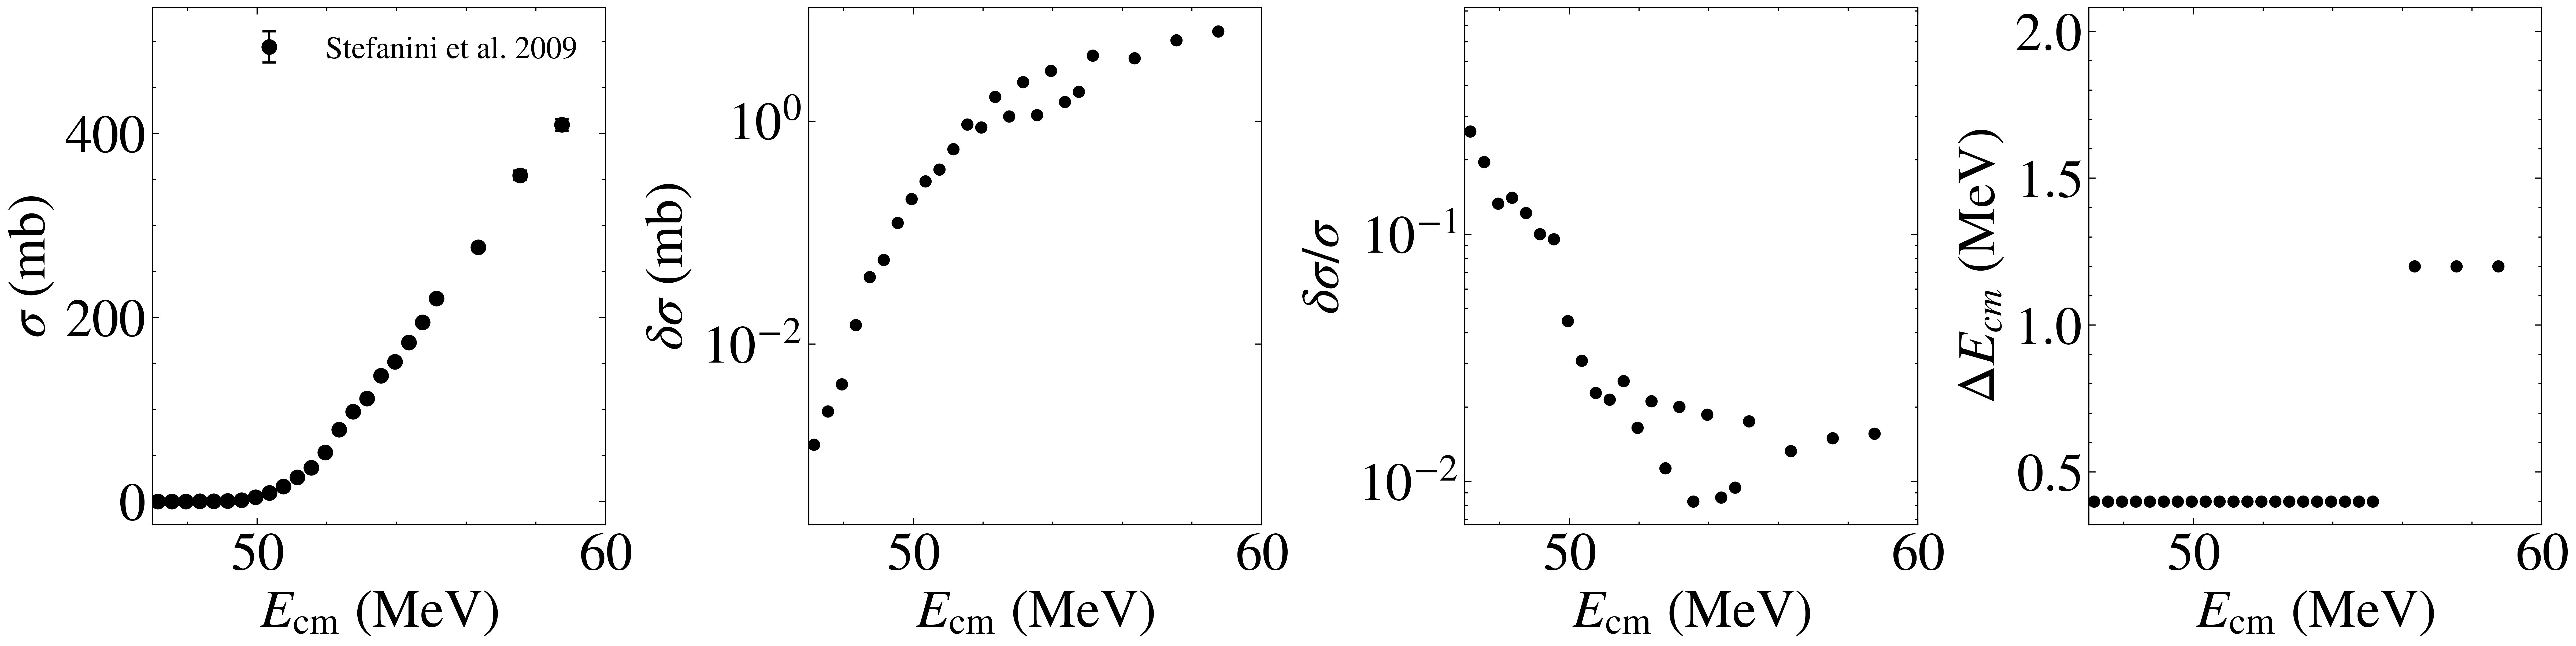

In [5]:
#### SYSTEM ####

dirname = EXPERIMENT_DATA_DIR / "48Ca48Ca_exp"
system = "$^{48}$Ca+$^{48}$Ca"
fileprefix = dirname

expfiles = [ 'expStef.dat' ]
explabel = [ 'Stefanini et al. 2009']



expmarker = [ 'o', 's', 'v' ]
expcolor = [ 'k', 'g', 'r' ]

exp = []

for file in expfiles:
    tmpdf = pd.read_csv(os.path.join(dirname,file),sep=r"\s+",names=['Ecm','Sigma','Error'])
    if(tmpdf['Ecm'].iloc[0] > tmpdf['Ecm'].iloc[-1]):
        exp.append(tmpdf.iloc[::-1])
    else:
        exp.append(tmpdf)

xmin = 47.0
xmax = 60.0


# --- 1) Compute & print resolutions per experiment ---
for i in range(len(exp)):
    E_data     = exp[i]['Ecm'].to_numpy()
    error_data = exp[i]['Error'].to_numpy()
    Sigma_data = exp[i]['Sigma'].to_numpy()
    
    safe_label = explabel[i].replace(" ", "")
    np.save(DATA_DIR / f"E_{safe_label}.npy", E_data)
    np.save(DATA_DIR / f"sigma_{safe_label}.npy", Sigma_data)
    np.save(DATA_DIR / f"error_{safe_label}.npy", error_data)
    # stop at closest point to 80 MeV
    stop = np.argmin(np.abs(E_data - 55.0))
    E_sorted = np.sort(E_data[:stop])
    dE       = np.diff(E_sorted)
    mean_dE = dE.mean()
    std_dE  = dE.std()
    cv      = std_dE/mean_dE
    print(f"Mean spacing = {mean_dE:.2f} MeV")
    print(f"Std spacing  = {std_dE:.2f} MeV")
    print(f"CV           = {cv:.2f}")

    if dE.size:
        print(f"Average resolution for {explabel[i]}: {dE.mean():.2f} MeV")
        print(f"Median   resolution for {explabel[i]}: {np.median(dE):.2f} MeV")
        print(f"Min/Max  resolution for {explabel[i]}: {dE.min():.2f}/{dE.max():.2f} MeV")
    else:
        print(f"No resolution data for {explabel[i]} (too few points).")
# — plotting —
fig, axes = plt.subplots(1, 4, figsize=(16,4), sharex=True, constrained_layout=True)
#fig.suptitle(system, fontsize=30, y=1.1)

# σ(E)
ax = axes[0]
for df, m, c, lbl in zip(exp, expmarker, expcolor, explabel):
    if df['Error'].any():
        ax.errorbar(
            df['Ecm'], 
            df['Sigma'], 
            yerr=df['Error'],         # <-- add y-error here
            fmt=m,                    # marker style
            color=c, 
            label=lbl,
            capsize=3,                # little horizontal caps on the error bars
            linestyle='none',         # no connecting line
            markersize=6
        )
    else:
        ax.scatter(df['Ecm'], df['Sigma'], 
                   s=20, marker=m, color=c, label=lbl)
ax.set_xlabel(r'$E_{\rm cm}$ (MeV)')
ax.set_ylabel(r'$\sigma$ (mb)')
ax.set_xlim(xmin, xmax)
#ax.grid(True, linestyle='--', alpha=0.4)
ax.legend(fontsize=14)
#ax.set_title(r'Absolute cross-section')

# δσ(E)
ax = axes[1]
for df, m, c in zip(exp, expmarker, expcolor):
    ax.scatter(df['Ecm'], df['Error'], 
               s=20, marker=m, color=c)
ax.set_xlabel(r'$E_{\rm cm}$ (MeV)')
ax.set_ylabel(r'$\delta\sigma$ (mb)')
ax.set_yscale('log')
ax.set_xlim(xmin, xmax)
#ax.grid(True, which='both', linestyle='--', alpha=0.4)
#ax.set_title(system, fontsize=24)

# δσ/σ
ax = axes[2]
for df, m, c in zip(exp, expmarker, expcolor):
    ax.scatter(df['Ecm'], df['Error']/df['Sigma'], 
               s=20, marker=m, color=c)
ax.set_xlabel(r'$E_{\rm cm}$ (MeV)')
ax.set_ylabel(r'$\delta\sigma/\sigma$')
ax.set_yscale('log')
ax.set_xlim(xmin, xmax)

# --- 5) Plot del E ---
#plt.figure(figsize=(8,5))
ax = axes[3]
for df, m, c in zip(exp, expmarker, expcolor):
    ax.scatter(df['Ecm'][1:], np.diff(df['Ecm']), 
               s=20, marker=m, color=c)
ax.set_xlabel(r'$E_{\rm cm}$ (MeV)')
ax.set_ylabel(r'$\Delta E_{cm}$ (MeV)')
ax.set_xlim(xmin, xmax)
#plt.tight_layout()
fig.savefig(PLOT_DIR / '48Ca48Ca.png', dpi=300)
plt.show()

### General Conclusions: 
- In general, 0.4 MeV $\leq \Delta E \leq$ 1.0 MeV near barrier where there is curvature.
- Reported uncertainties of available data are typically order of 1 mb near barrier.